<a href="https://colab.research.google.com/github/viniciuspaulo99/colad_ad05/blob/main/api/desafio_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![title](https://ik.imagekit.io/vzr6ryejm/colab/jupyter_notebook-API.drawio.png)

# 🐶🐱 Versão 2: várias imagens

Pede às duas APIs várias imagens de uma vez e salva cada uma com um nome diferente (`dog_1`, `dog_2`, `cat_1`, `cat_2`...) em `imagens/multiplas/`.

> No Colab os arquivos ficam em `/content` e **são apagados quando a sessão termina**. Baixe o que quiser guardar pelo painel de arquivos (ícone de pasta, à esquerda).

> ✍️ **Atenção:** algumas linhas estão incompletas. Substitua cada `___` para completar o código, nas linhas marcadas com `# complete esta linha`.

## 1. Configuração

In [ ]:
import os
import requests
from IPython.display import Image, display

QUANTIDADE = 5  # quantas imagens de cada animal

pasta = os.path.join(os.getcwd(), 'imagens/multiplas')
os.makedirs(pasta, exist_ok=True)

## 2. Função para baixar e salvar

In [ ]:
def salvar(img_url, nome):
    """Baixa a imagem e salva na pasta com o nome (mantém a extensão original)."""
    extensao = os.path.splitext(img_url)[1] or '.jpg'
    caminho = os.path.join(pasta, nome + extensao)
    img_data = requests.get(img_url).content
    with open(caminho, 'wb') as handler:
        handler.write(img_data)
    print(f"Salvo: {caminho}")
    return caminho

## 3. Cachorros
A API aceita `/random/N` para devolver N imagens de uma vez.

In [ ]:
caminhos_caes = []
resposta = requests.get(f'https://dog.ceo/api/breeds/image/random/{QUANTIDADE}')  # complete esta linha
for i, img_url in enumerate(resposta.json()['message'], start=1):  # complete esta linha
    caminhos_caes.append(salvar(img_url, f'dog_{i}'))  # complete esta linha

Salvo: /content/imagens/multiplas/dog_1.jpg
Salvo: /content/imagens/multiplas/dog_2.jpg
Salvo: /content/imagens/multiplas/dog_3.jpg
Salvo: /content/imagens/multiplas/dog_4.jpg
Salvo: /content/imagens/multiplas/dog_5.jpg


## 4. Gatos
A API aceita `?limit=N`.

In [ ]:
caminhos_gatos = []
resposta = requests.get(f'https://api.thecatapi.com/v1/images/search?limit={QUANTIDADE}')  # complete esta linha
for i, item in enumerate(resposta.json(), start=1):
    caminhos_gatos.append(salvar(item['url'], f'cat_{i}'))  # complete esta linha

print("Pronto!")

Salvo: /content/imagens/multiplas/cat_1.jpg
Salvo: /content/imagens/multiplas/cat_2.jpg
Salvo: /content/imagens/multiplas/cat_3.jpg
Salvo: /content/imagens/multiplas/cat_4.jpg
Salvo: /content/imagens/multiplas/cat_5.jpg
Pronto!


## 5. Visualizar as imagens

dog_1.jpg


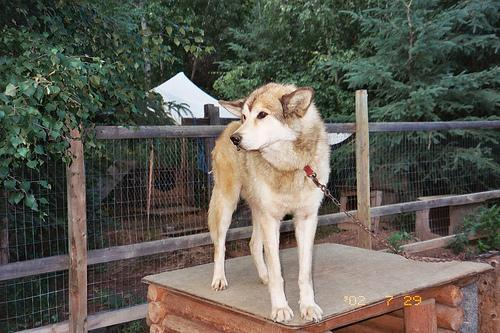

dog_2.jpg


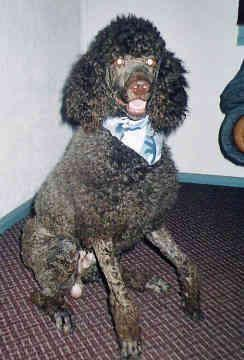

dog_3.jpg


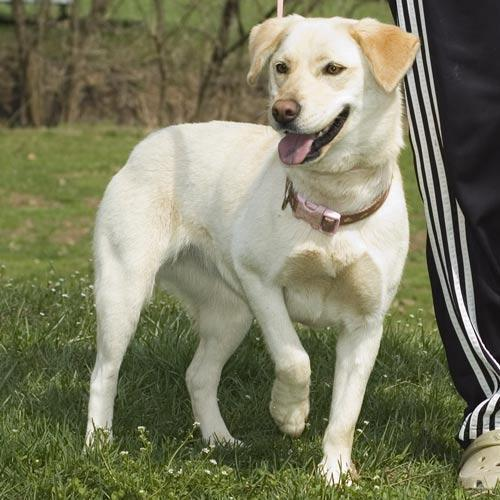

dog_4.jpg


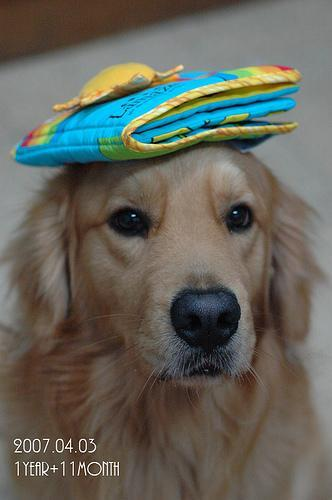

dog_5.jpg


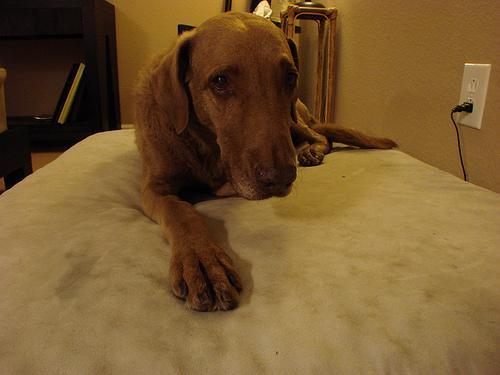

cat_1.jpg


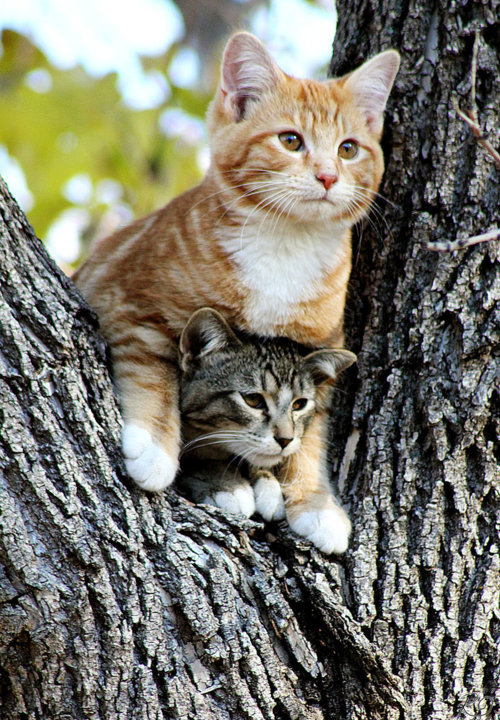

cat_2.jpg


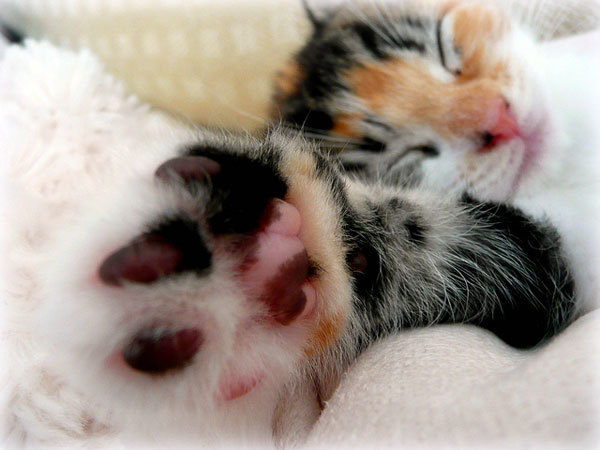

cat_3.jpg


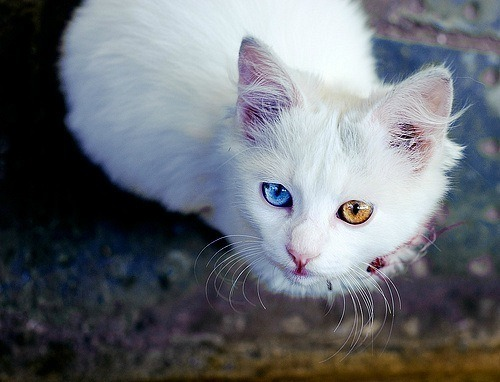

cat_4.jpg


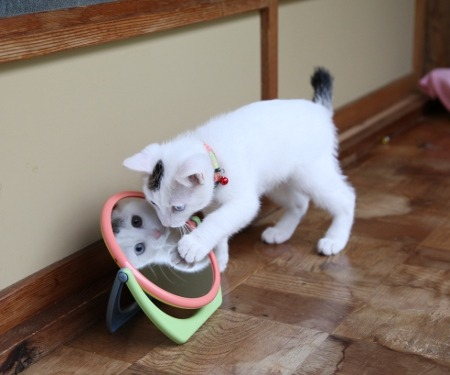

cat_5.jpg


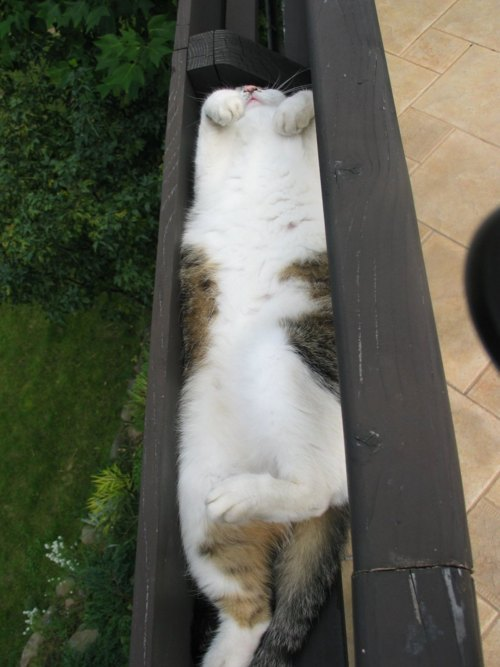

In [ ]:
for c in caminhos_caes + caminhos_gatos:
    print(os.path.basename(c))
    display(Image(filename=c, width=250))

## 6. (Opcional) Baixar tudo para o seu computador

In [ ]:
import shutil

shutil.make_archive('multiplas', 'zip', pasta)
try:
    from google.colab import files
    files.download('multiplas.zip')
except ImportError:
    print("Fora do Colab: o arquivo multiplas.zip foi criado na pasta atual.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>